Run this notebook from the project folder. Set `dataset_path` below to the extracted CIC-IDS parquet file. Run the preprocessing cells before training to create the audited checkpoints.

# Data Cleaning and Splitting

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import gc

Load Data

In [2]:
from pathlib import Path
import json

dataset_path = Path(".local-ml/inputs/cic-collection.parquet")
run_dir = Path(".local-ml/audited")
run_dir.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(dataset_path)

In [3]:
print(f"Loaded {len(df)} rows and {len(df.columns)} columns")
df.head()

Loaded 9167581 rows and 59 columns


   Flow Duration  Total Fwd Packets  ...   Label  ClassLabel
0              4                  2  ...  Benign      Benign
1              1                  2  ...  Benign      Benign
2              3                  2  ...  Benign      Benign
3              1                  2  ...  Benign      Benign
4            609                  7  ...  Benign      Benign

[5 rows x 59 columns]

# Pre-Processing Data

In [4]:
df.columns


Index(['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
       'Fwd Packets Length Total', 'Bwd Packets Length Total',
       'Fwd Packet Length Max', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s',
       'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max',
       'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std',
       'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean',
       'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags',
       'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s',
       'Bwd Packets/s', 'Packet Length Max', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count',
       'URG Flag Count', 'Avg Packet Size', 'Avg Fwd Segment Size',
       'Avg Bwd Segment Size', 'Subflow Fwd Packets', 'Subflow Fwd Bytes',
       'Subflow Bwd Packets', 'Subflow Bwd By

In [5]:
df['ClassLabel'].unique().tolist()

['Benign', 'Botnet', 'Bruteforce', 'DoS', 'DDoS', 'Infiltration', 'Portscan', 'Webattack']

In [6]:
df.columns = df.columns.str.strip()
repeated_names = df.columns[df.columns.duplicated()].unique().tolist()
print("Repeated column names after trimming:", repeated_names)
if repeated_names:
    raise ValueError(f"Resolve repeated column names before selecting predictors: {repeated_names}")

raw_counts = df["ClassLabel"].value_counts().sort_index()
print("Raw class counts:")
print(raw_counts)
df.drop(columns=["Label"], inplace=True)

Repeated column names after trimming: []
Raw class counts:
ClassLabel
Benign          7186189
Botnet           145968
Bruteforce       103244
DDoS            1234729
DoS              397344
Infiltration      94857
Portscan           2255
Webattack          2995
Name: count, dtype: int64


This has extreme class imbalance, so we will use a stratified split

In [7]:
input_rows = len(df)
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
clean_counts = df["ClassLabel"].value_counts().sort_index()
print(f"Removed {input_rows - len(df):,} rows with missing or nonfinite values.")

Removed 0 rows with missing or nonfinite values.


### Audit exact duplicates before splitting

The audit compares the original numeric values. It keeps one copy of each vector with a single class label and excludes every row for vectors with conflicting labels. This treats equal feature vectors as one unit for evaluation because the dataset has no event identifiers to distinguish their origins.

#### Duplicate feature columns

These four pairs had identical values across all 9,167,581 input rows. The audit kept one column from each pair.

| Removed column | Retained column |
| --- | --- |
| Avg Fwd Segment Size | Fwd Packet Length Mean |
| Avg Bwd Segment Size | Bwd Packet Length Mean |
| Subflow Fwd Packets | Total Fwd Packets |
| Subflow Bwd Packets | Total Backward Packets |

# Label Encoding and Splitting

In [8]:
feature_names = df.columns.drop("ClassLabel")
bounds = {name: (df[name].min(), df[name].max()) for name in feature_names}
identical_columns = {}
retained_columns = []
for name in feature_names:
    for other in retained_columns:
        if bounds[name] == bounds[other] and np.array_equal(df[name], df[other]):
            identical_columns[name] = other
            break
    else:
        retained_columns.append(name)
dataset_constants = [name for name in retained_columns if bounds[name][0] == bounds[name][1]]
df.drop(columns=list(identical_columns), inplace=True)

# Hash chunks to limit memory use. Verify every adjacent pair in a hash group
# against the original features before using the group to remove any rows.
fingerprints = np.empty(len(df), dtype=np.uint64)
for start in range(0, len(df), 100_000):
    batch = df.iloc[start:start + 100_000][retained_columns].copy()
    for name in batch.select_dtypes(include="floating"):
        batch[name] = batch[name].mask(batch[name] == 0, 0.0)
    fingerprints[start:start + len(batch)] = pd.util.hash_pandas_object(batch, index=False).to_numpy()

order = np.argsort(fingerprints, kind="stable")
matching = fingerprints[order[1:]] == fingerprints[order[:-1]]
left = order[:-1][matching]
right = order[1:][matching]
for name in retained_columns:
    values = df[name].to_numpy()
    if not np.array_equal(values[left], values[right]):
        raise RuntimeError(f"Feature hash collision detected while comparing {name}.")

labels = df["ClassLabel"].to_numpy()
group = np.r_[0, np.cumsum(~matching)]
conflict_groups = np.unique(group[1:][matching & (labels[order[1:]] != labels[order[:-1]])])
conflicting = np.isin(group, conflict_groups)
first = np.r_[True, ~matching]
keep = np.sort(order[first & ~conflicting])
duplicate_audit = {
    "inputRows": input_rows,
    "cleanRows": len(df),
    "missingOrNonfiniteRows": input_rows - len(df),
    "inputFeatures": len(feature_names),
    "repeatedColumnNames": repeated_names,
    "identicalColumns": identical_columns,
    "datasetConstantFeatures": dataset_constants,
    "repeatedFeatureGroups": int((np.diff(np.r_[np.flatnonzero(first), len(df)]) > 1).sum()),
    "sameLabelDuplicateRowsRemoved": int((~first & ~conflicting).sum()),
    "conflictingFeatureGroups": len(conflict_groups),
    "conflictingRowsRemoved": int(conflicting.sum()),
    "retainedRows": len(keep),
    "rawCounts": {key: int(value) for key, value in raw_counts.items()},
    "cleanCounts": {key: int(value) for key, value in clean_counts.items()},
}
assert len(df) == len(keep) + duplicate_audit["sameLabelDuplicateRowsRemoved"] + duplicate_audit["conflictingRowsRemoved"]
del batch, fingerprints, order, matching, left, right, values, group, labels, conflicting, first
df = df.iloc[keep]
le = LabelEncoder()
y = le.fit_transform(df.pop("ClassLabel"))
X = df
del df

train_indices, holdout_indices = train_test_split(
    np.arange(len(y)), test_size=0.30, random_state=42, stratify=y,
)
val_indices, test_indices = train_test_split(
    holdout_indices, test_size=0.50, random_state=42, stratify=y[holdout_indices],
)
target_names = le.classes_.tolist()
duplicate_audit["retainedCounts"] = dict(zip(target_names, np.bincount(y).tolist()))
duplicate_audit["trainFlows"] = len(train_indices)
duplicate_audit["validationFlows"] = len(val_indices)
duplicate_audit["testFlows"] = len(test_indices)
print(json.dumps(duplicate_audit, indent=2))

{
  "inputRows": 9167581,
  "cleanRows": 9167581,
  "missingOrNonfiniteRows": 0,
  "inputFeatures": 57,
  "repeatedColumnNames": [],
  "identicalColumns": {
    "Avg Fwd Segment Size": "Fwd Packet Length Mean",
    "Avg Bwd Segment Size": "Bwd Packet Length Mean",
    "Subflow Fwd Packets": "Total Fwd Packets",
    "Subflow Bwd Packets": "Total Backward Packets"
  },
  "datasetConstantFeatures": [],
  "repeatedFeatureGroups": 310,
  "sameLabelDuplicateRowsRemoved": 310,
  "conflictingFeatureGroups": 7,
  "conflictingRowsRemoved": 14,
  "retainedRows": 9167257,
  "rawCounts": {
    "Benign": 7186189,
    "Botnet": 145968,
    "Bruteforce": 103244,
    "DDoS": 1234729,
    "DoS": 397344,
    "Infiltration": 94857,
    "Portscan": 2255,
    "Webattack": 2995
  },
  "cleanCounts": {
    "Benign": 7186189,
    "Botnet": 145968,
    "Bruteforce": 103244,
    "DDoS": 1234729,
    "DoS": 397344,
    "Infiltration": 94857,
    "Portscan": 2255,
    "Webattack": 2995
  },
  "retainedCounts": {
 

### Sample the training split and filter constant features

Keep a stratified 20% sample of the training partition. Learn the constant-feature mask on that sample and reuse the same columns in validation and test.

In [9]:
_, sample_indices = train_test_split(
    train_indices, test_size=0.20, random_state=42, stratify=y[train_indices],
)
train_sample = X.iloc[sample_indices]
constant_features = train_sample.columns[train_sample.nunique() == 1].tolist()
model_features = train_sample.columns.drop(constant_features).tolist()

X_train = train_sample[model_features]
X_val = X.iloc[val_indices][model_features]
X_test = X.iloc[test_indices][model_features]
y_train = y[sample_indices]
y_val = y[val_indices]
y_test = y[test_indices]
del X, y, train_sample
gc.collect()

duplicate_audit["trainingConstantFeatures"] = constant_features
duplicate_audit["trainingSampleFlows"] = len(X_train)
duplicate_audit["modelFeatures"] = model_features
print("Removed constant training features:", constant_features)
print(f"{len(model_features)} predictors")
print(f"Training sample: {len(X_train):,} / {len(train_indices):,}")
print(f"Validation: {len(X_val):,}")
print(f"Test: {len(X_test):,}")

Removed constant training features: []
53 predictors
Training sample: 1,283,416 / 6,417,079
Validation: 1,375,089
Test: 1,375,089


Creating a checkpoint to refresh cache

In [10]:
print("Saving clean checkpoints to disk...")

# Combine X and y temporarily to save them as single files per fold
# X_train is now your 1.28M row subsample
train_df = X_train.copy()
train_df['Target'] = y_train
train_df.to_parquet(run_dir / "train.parquet")
del train_df

val_df = X_val.copy()
val_df['Target'] = y_val
val_df.to_parquet(run_dir / "val.parquet")
del val_df

test_df = X_test.copy()
test_df['Target'] = y_test
test_df.to_parquet(run_dir / "test.parquet")
del test_df

print("Checkpoints saved successfully!")

del X_train, X_val, X_test, y_train, y_val, y_test
gc.collect()

Saving clean checkpoints to disk...
Checkpoints saved successfully!


0

# The Baseline Model & Preprocessing Pipeline

In [11]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

print("Loading clean data from checkpoints...")
train = pd.read_parquet(run_dir / "train.parquet")
X_train = train.drop(columns=['Target'])
y_train = train['Target']

val = pd.read_parquet(run_dir / "val.parquet")
X_val = val.drop(columns=['Target'])
y_val = val['Target']

# We don't load test yet to strictly prevent leakage
print("\nBuilding Preprocessing Pipeline and Baseline Model...")
baseline_pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('logreg', SGDClassifier(
        loss='log_loss',
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ))
])
print("Training Baseline Model...")
baseline_pipeline.fit(X_train, y_train)

print("\nPredicting on Validation Set...")
y_val_pred = baseline_pipeline.predict(X_val)

print("\n" + "="*50)
print(" BASELINE MODEL PERFORMANCE (Validation Set) ")
print("="*50)
print(f"Accuracy:       {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Macro F1-Score: {f1_score(y_val, y_val_pred, average='macro'):.4f}")
print(f"Weighted F1:    {f1_score(y_val, y_val_pred, average='weighted'):.4f}")
print("\nDetailed Classification Report:")
target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']
print(classification_report(y_val, y_val_pred, labels=range(len(target_names)), target_names=target_names, zero_division=0))

Loading clean data from checkpoints...

Building Preprocessing Pipeline and Baseline Model...
Training Baseline Model...

Predicting on Validation Set...

 BASELINE MODEL PERFORMANCE (Validation Set) 
Accuracy:       0.2968
Macro F1-Score: 0.0864
Weighted F1:    0.4036

Detailed Classification Report:
              precision    recall  f1-score   support

      Benign       0.77      0.35      0.48   1077881
      Botnet       0.00      0.00      0.00     21895
  Bruteforce       0.00      0.00      0.00     15487
        DDoS       0.21      0.15      0.17    185209
         DoS       0.00      0.00      0.00     59601
Infiltration       0.02      0.04      0.03     14228
    Portscan       0.00      0.12      0.00       338
   Webattack       0.00      0.20      0.00       450

    accuracy                           0.30   1375089
   macro avg       0.13      0.11      0.09   1375089
weighted avg       0.64      0.30      0.40   1375089



C:\Users\viraa_x3dnped\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


The linear baseline uses class-weighted logistic loss. Its aggregate accuracy and per-class report above show how those settings affect the trade-off between detecting attacks and raising false alarms.

## Training the Main Models (Tree Ensembles)

--- Training Tree Ensembles & Generating Visuals ---

Training Random Forest...
Training Scikit-Learn Gradient Boosting...
Training XGBoost...

 RANDOM FOREST (Validation Set) 
Accuracy:       0.7818
Macro F1-Score: 0.7656

 GRADIENT BOOSTING (Validation Set) 
Accuracy:       0.9869
Macro F1-Score: 0.7354

 XGBOOST (Validation Set) 
Accuracy:       0.9888
Macro F1-Score: 0.8503


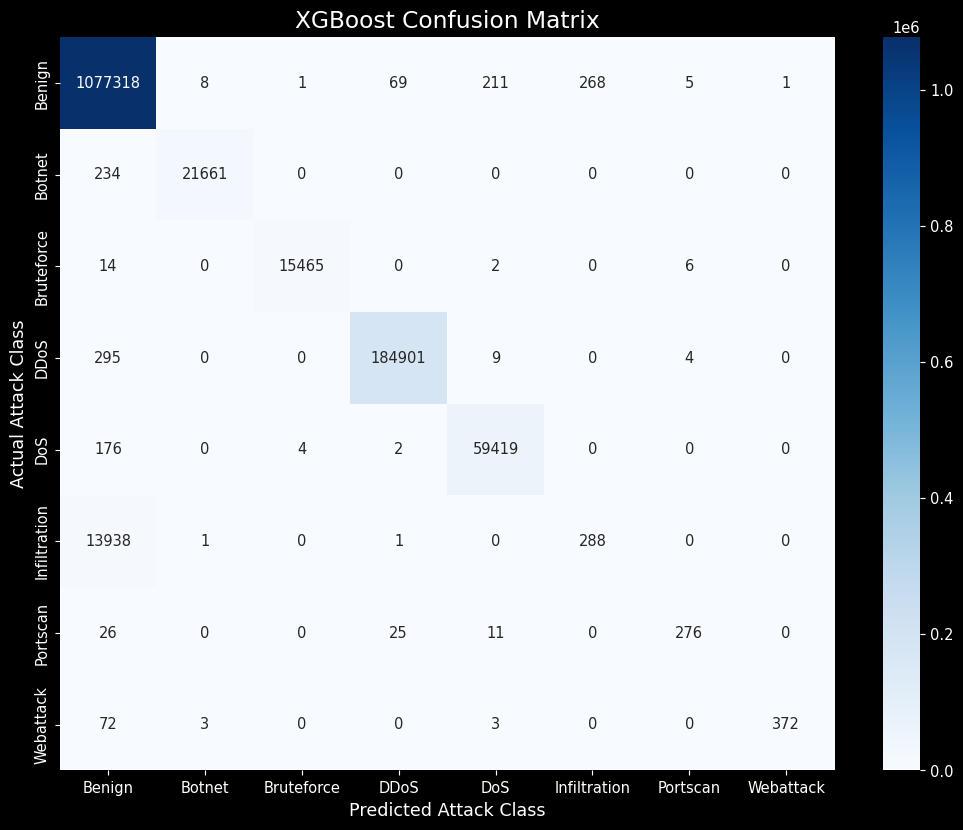

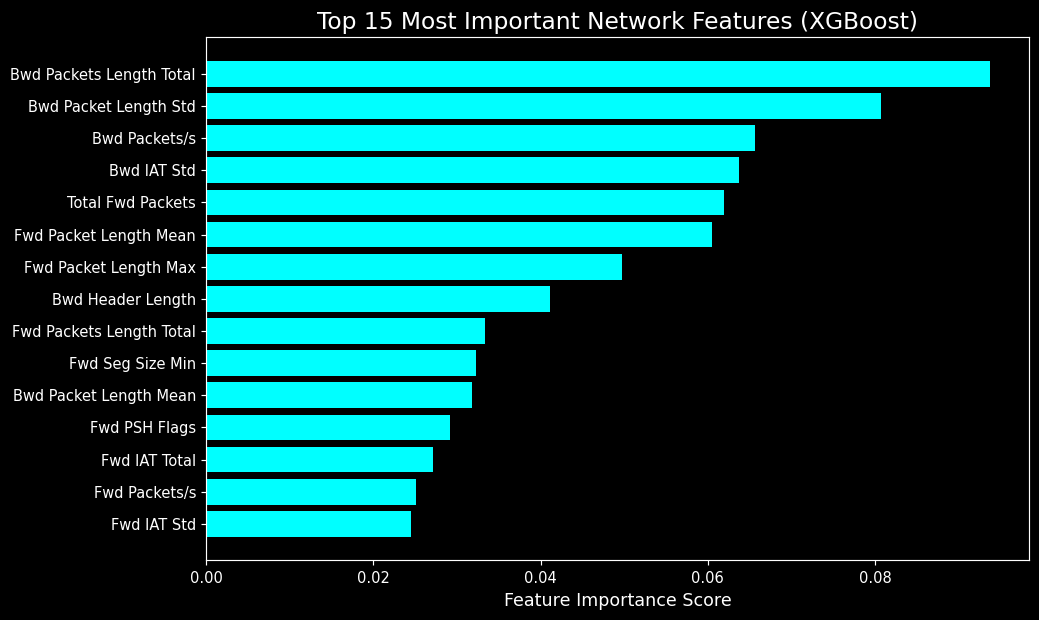

In [12]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

print("--- Training Tree Ensembles & Generating Visuals ---")

target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']

# 1. Random Forest
print("\nTraining Random Forest...")
rf_model = RandomForestClassifier(n_estimators=50, max_depth=15, class_weight='balanced', n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Scikit-Learn Gradient Boosting (Using the blazing-fast Hist variant)
print("Training Scikit-Learn Gradient Boosting...")
gb_model = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42)
gb_model.fit(X_train, y_train)

# 3. XGBoost
print("Training XGBoost...")
xgb_model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, tree_method='hist', n_jobs=-1, random_state=42)
xgb_model.fit(X_train, y_train)

# --- EVALUATION ---
models = {'Random Forest': rf_model, 'Gradient Boosting': gb_model, 'XGBoost': xgb_model}
best_model_name = "XGBoost" # We will visualize XGBoost by default

for name, model in models.items():
    print("\n" + "="*40)
    print(f" {name.upper()} (Validation Set) ")
    print("="*40)
    y_pred = model.predict(X_val)
    print(f"Accuracy:       {accuracy_score(y_val, y_pred):.4f}")
    print(f"Macro F1-Score: {f1_score(y_val, y_pred, average='macro'):.4f}")

    if name == best_model_name:
        xgb_preds = y_pred # Save for the confusion matrix

# --- VISUALIZATIONS FOR REPORT ---
plt.style.use('dark_background')

# Plot 1: Confusion Matrix (Proves where the model struggles)
fig, ax = plt.subplots(figsize=(10, 8))
cm = confusion_matrix(y_val, xgb_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=ax)
ax.set_title("XGBoost Confusion Matrix", fontsize=16)
ax.set_ylabel("Actual Attack Class", fontsize=12)
ax.set_xlabel("Predicted Attack Class", fontsize=12)
plt.tight_layout()
plt.show()

# Plot 2: Feature Importance (Shows what network features matter most)
fig, ax = plt.subplots(figsize=(10, 6))
# Get top 15 features from XGBoost
importances = xgb_model.feature_importances_
indices = np.argsort(importances)[-15:] # Top 15

ax.barh(range(len(indices)), importances[indices], align='center', color='cyan')
ax.set_yticks(range(len(indices)))
ax.set_yticklabels([X_train.columns[i] for i in indices])
ax.set_title("Top 15 Most Important Network Features (XGBoost)", fontsize=16)
ax.set_xlabel("Feature Importance Score", fontsize=12)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import classification_report

print("--- DETAILED CLASSIFICATION REPORTS (8 CLASSES) ---")
target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']

# Assuming models are still in memory as rf_model, gb_model, and xgb_model
models = {
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model,
    'XGBoost': xgb_model
}

for name, model in models.items():
    print("\n" + "="*55)
    print(f" {name.upper()} - FULL CLASSIFICATION REPORT ")
    print("="*55)

    # Predict on the unscaled validation set
    y_pred = model.predict(X_val)

    # Print the detailed per-class report
    print(classification_report(y_val, y_pred, labels=range(len(target_names)), target_names=target_names, zero_division=0))

--- DETAILED CLASSIFICATION REPORTS (8 CLASSES) ---

 RANDOM FOREST - FULL CLASSIFICATION REPORT 
              precision    recall  f1-score   support

      Benign       1.00      0.72      0.84   1077881
      Botnet       0.96      1.00      0.98     21895
  Bruteforce       1.00      1.00      1.00     15487
        DDoS       0.99      1.00      0.99    185209
         DoS       0.97      1.00      0.98     59601
Infiltration       0.04      0.89      0.08     14228
    Portscan       0.82      0.88      0.85       338
   Webattack       0.26      0.89      0.40       450

    accuracy                           0.78   1375089
   macro avg       0.75      0.92      0.77   1375089
weighted avg       0.98      0.78      0.86   1375089


 GRADIENT BOOSTING - FULL CLASSIFICATION REPORT 
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99   1077881
      Botnet       1.00      0.99      0.99     21895
  Bruteforce       1.00      1.00     

Generating Per-Class F1-Score Comparison Plot...


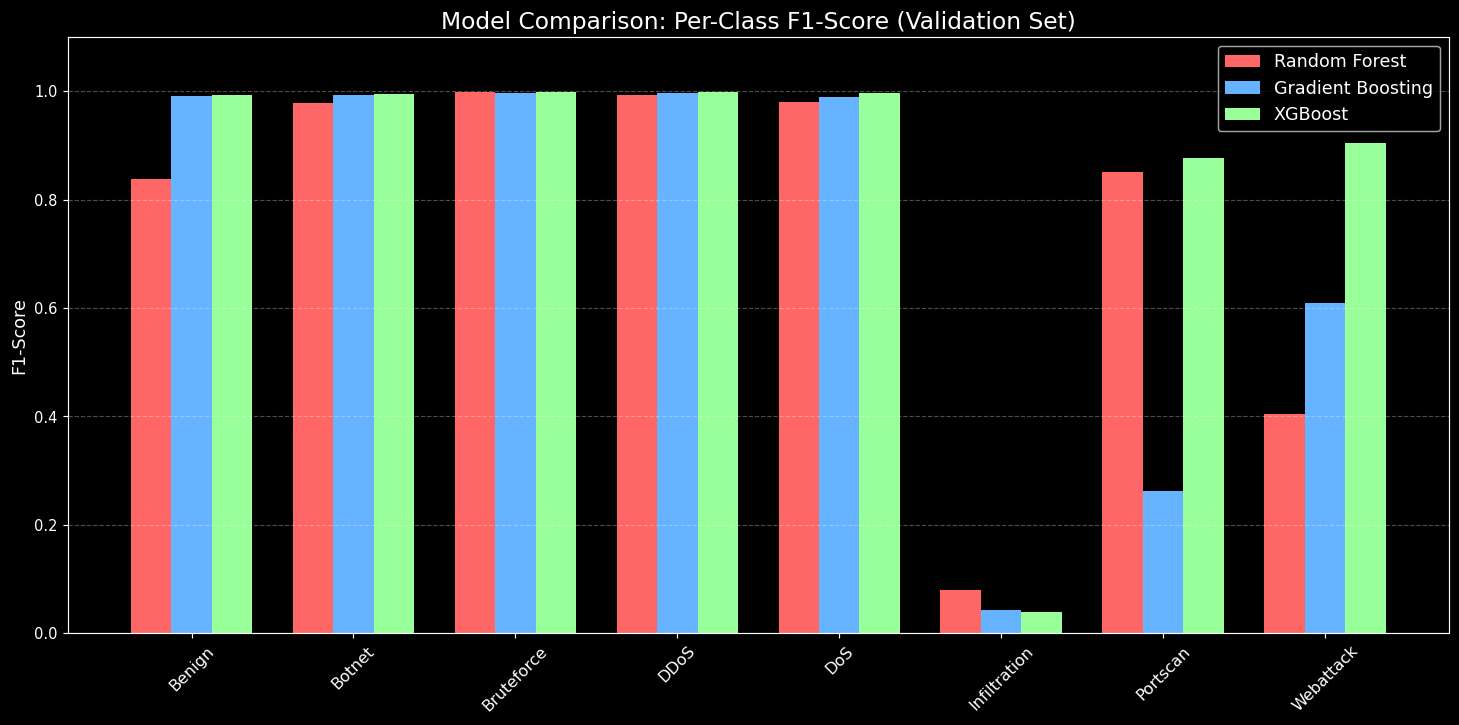

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score

print("Generating Per-Class F1-Score Comparison Plot...")

# 1. Get predictions (this is very fast for trees)
y_pred_rf = rf_model.predict(X_val)
y_pred_gb = gb_model.predict(X_val)
y_pred_xgb = xgb_model.predict(X_val)

# 2. Calculate per-class F1-scores (average=None returns an array of scores for all 8 classes)
f1_rf = f1_score(y_val, y_pred_rf, average=None)
f1_gb = f1_score(y_val, y_pred_gb, average=None)
f1_xgb = f1_score(y_val, y_pred_xgb, average=None)

# 3. Plotting Setup
target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']
x = np.arange(len(target_names))
width = 0.25  # Width of the bars

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(14, 7))

# 4. Create the grouped bars
ax.bar(x - width, f1_rf, width, label='Random Forest', color='#ff6666')
ax.bar(x, f1_gb, width, label='Gradient Boosting', color='#66b3ff')
ax.bar(x + width, f1_xgb, width, label='XGBoost', color='#99ff99')

# 5. Formatting
ax.set_ylabel('F1-Score', fontsize=12)
ax.set_title('Model Comparison: Per-Class F1-Score (Validation Set)', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(target_names, rotation=45, fontsize=11)
ax.legend(fontsize=12)
ax.set_ylim([0.0, 1.1])
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# MLP Pipeline

In [15]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import classification_report, accuracy_score, f1_score
import time

print("Building Scaler and Enhanced MLP...")
#Three layer deep funnel (128->64->32) to capture complex non-linear attacks
mlp_pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        batch_size=2048,           # CRITICAL: Processes data in larger chunks, drastically cutting train time
        max_iter=200,              # Increased ceiling for epochs to ensure convergence
        early_stopping=True,       # Prevents overfitting and endless training
        n_iter_no_change=10,       # Waits for 10 epochs of no improvement before stopping
        learning_rate_init=0.001,  # Slower, more precise learning rate (the default)
        random_state=42
    ))
])

print("Training Enhanced MLP...")
start_time = time.time()
mlp_pipeline.fit(X_train, y_train)
print(f"MLP trained in {time.time() - start_time:.1f} seconds.")

print("\n" + "="*50)
print(" ENHANCED MLP PERFORMANCE (Validation Set) ")
print("="*50)
y_val_pred_mlp = mlp_pipeline.predict(X_val)
print(f"Accuracy:       {accuracy_score(y_val, y_val_pred_mlp):.4f}")
print(f"Macro F1-Score: {f1_score(y_val, y_val_pred_mlp, average='macro'):.4f}")
print("\nMLP Classification Report:")
print(classification_report(y_val, y_val_pred_mlp, labels=range(len(target_names)), target_names=target_names, zero_division=0))

Building Scaler and Enhanced MLP...
Training Enhanced MLP...
MLP trained in 97.9 seconds.

 ENHANCED MLP PERFORMANCE (Validation Set) 
Accuracy:       0.9263
Macro F1-Score: 0.6086

MLP Classification Report:
              precision    recall  f1-score   support

      Benign       0.93      0.98      0.96   1077881
      Botnet       0.99      0.97      0.98     21895
  Bruteforce       1.00      0.99      0.99     15487
        DDoS       0.97      0.70      0.81    185209
         DoS       0.69      0.84      0.76     59601
Infiltration       0.02      0.00      0.00     14228
    Portscan       0.04      0.00      0.01       338
   Webattack       0.92      0.22      0.35       450

    accuracy                           0.93   1375089
   macro avg       0.69      0.59      0.61   1375089
weighted avg       0.92      0.93      0.92   1375089



# Testing and Evaluation

Loading Unseen Test Set from Checkpoint...
Calculating Probabilities for One-vs-Rest ROC-AUC...


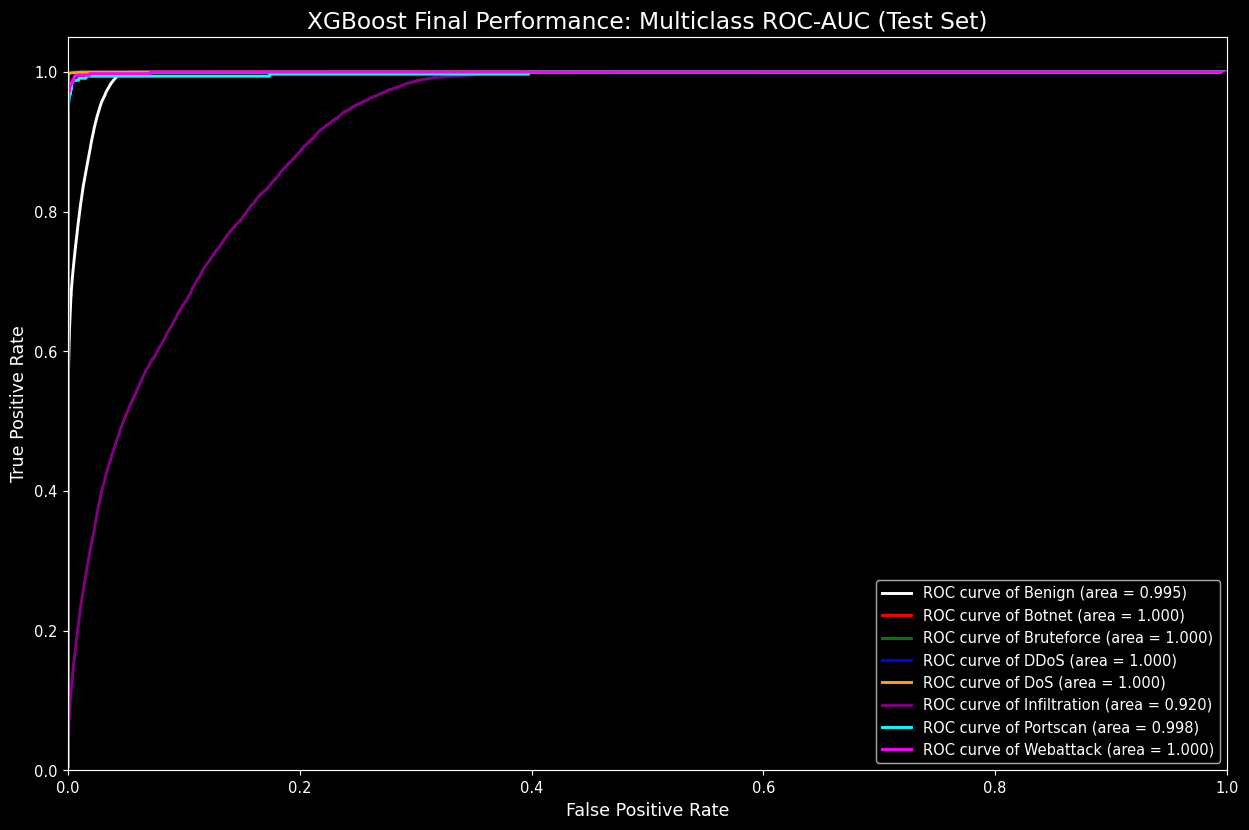

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

print("Loading Unseen Test Set from Checkpoint...")
test = pd.read_parquet(run_dir / "test.parquet")
X_test = test.drop(columns=['Target'])
y_test = test['Target']

target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']
n_classes = len(target_names)

print("Calculating Probabilities for One-vs-Rest ROC-AUC...")
# 1. Binarize the labels for OvR
y_test_bin = label_binarize(y_test, classes=range(n_classes))

# 2. Get prediction probabilities from the XGBoost model
y_score = xgb_model.predict_proba(X_test)

# 3. Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Plot all ROC curves
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 8))
colors = ['white', 'red', 'green', 'blue', 'orange', 'purple', 'cyan', 'magenta']

for i, color in zip(range(n_classes), colors):
    ax.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve of {target_names[i]} (area = {roc_auc[i]:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=2) # Diagonal guessing line
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('XGBoost Final Performance: Multiclass ROC-AUC (Test Set)', fontsize=16)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Precision-Recall Curve and Log Scale Distribution Plot

Generating Final Visuals: PR-Curve and Class Distribution...


notebook-cell-31:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



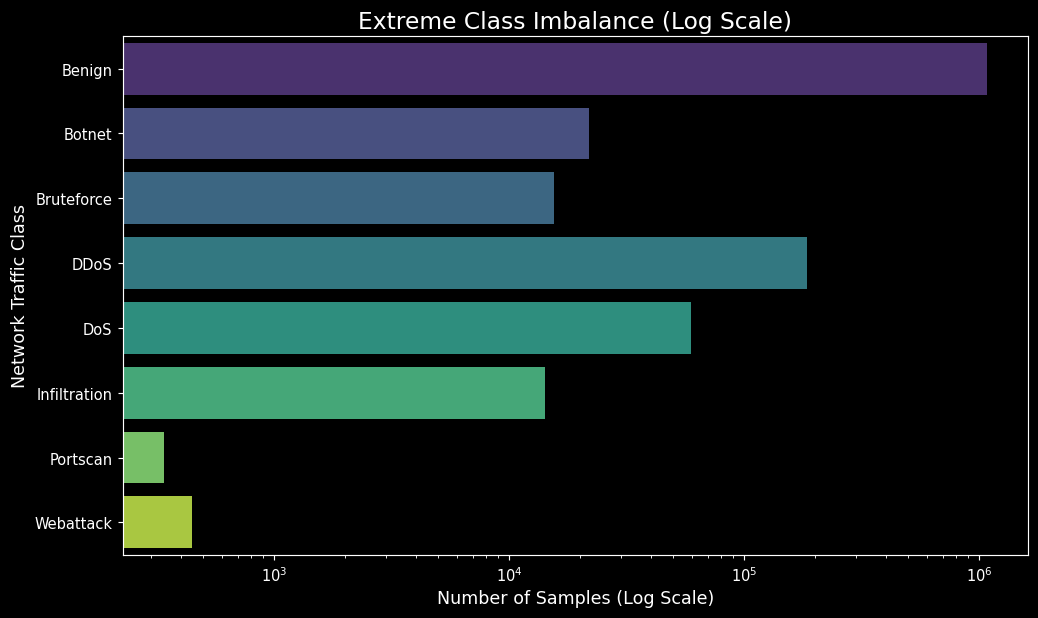

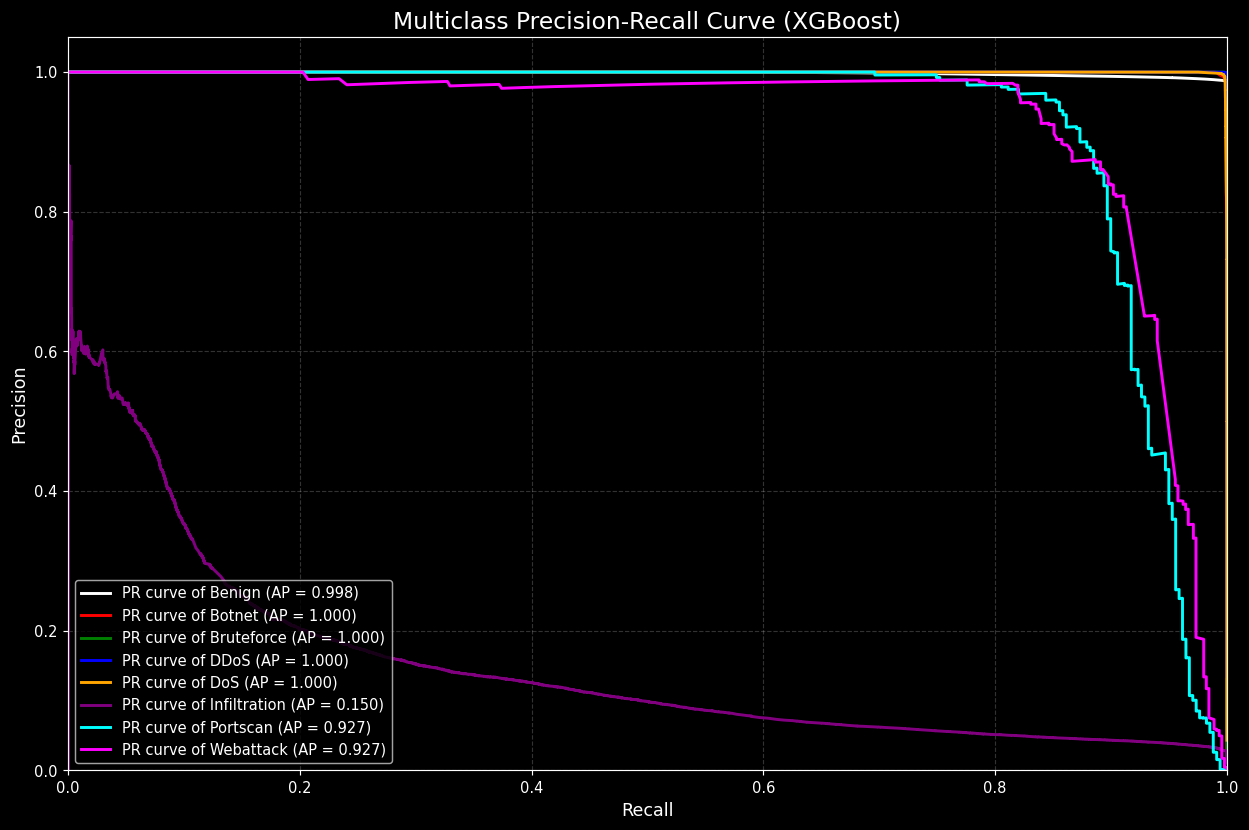

In [17]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import seaborn as sns

print("Generating Final Visuals: PR-Curve and Class Distribution...")

# 1. Log-Scale Class Distribution (Proves the extreme imbalance)
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10, 6))
# Count occurrences in the test set
class_counts = y_test.value_counts().sort_index()

# Bar plot with a logarithmic scale so the 450 Webattacks are visible next to 1M Benign
sns.barplot(x=class_counts.values, y=[target_names[i] for i in class_counts.index],
            palette='viridis', ax=ax)
ax.set_xscale('log')
ax.set_title('Extreme Class Imbalance (Log Scale)', fontsize=16)
ax.set_xlabel('Number of Samples (Log Scale)', fontsize=12)
ax.set_ylabel('Network Traffic Class', fontsize=12)
plt.tight_layout()
plt.show()

# 2. Multiclass Precision-Recall Curve (The gold standard for imbalanced data)
precision = dict()
recall = dict()
average_precision = dict()

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    average_precision[i] = average_precision_score(y_test_bin[:, i], y_score[:, i])

fig, ax = plt.subplots(figsize=(12, 8))
colors = ['white', 'red', 'green', 'blue', 'orange', 'purple', 'cyan', 'magenta']

for i, color in zip(range(n_classes), colors):
    ax.plot(recall[i], precision[i], color=color, lw=2,
             label=f'PR curve of {target_names[i]} (AP = {average_precision[i]:.3f})')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Multiclass Precision-Recall Curve (XGBoost)', fontsize=16)
ax.legend(loc="lower left")
plt.grid(alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

## Validation confusion matrices (audited local run)

Each matrix uses audited validation predictions. Rows are true classes and columns are predicted classes. Cell labels show exact flow counts, and color shows the percentage of each true class. The majority baseline predicts the most common training class for every flow.

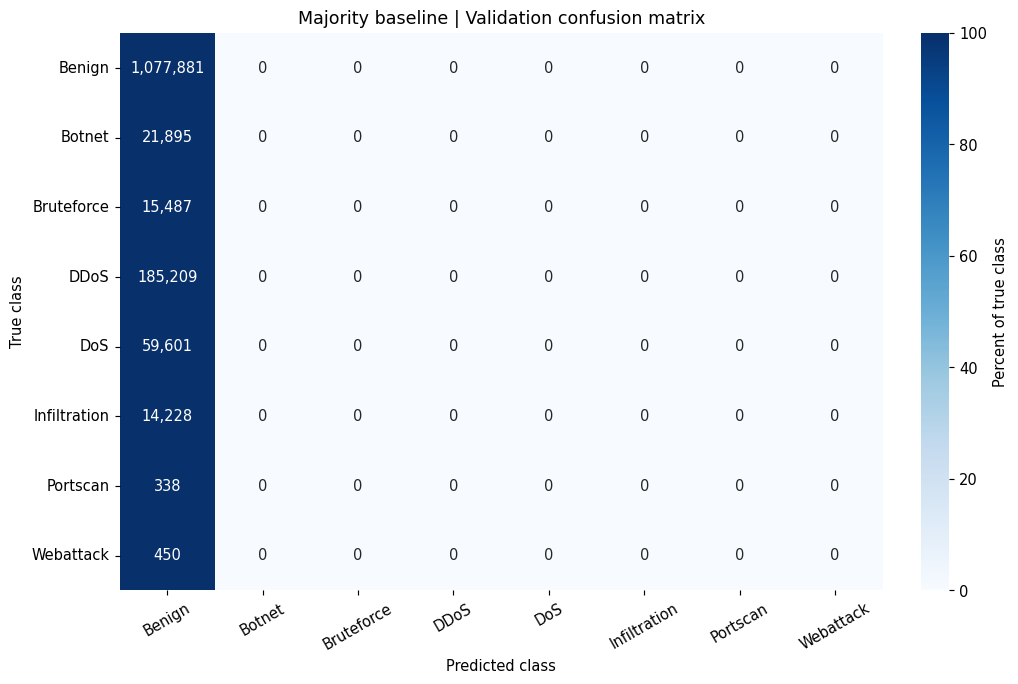

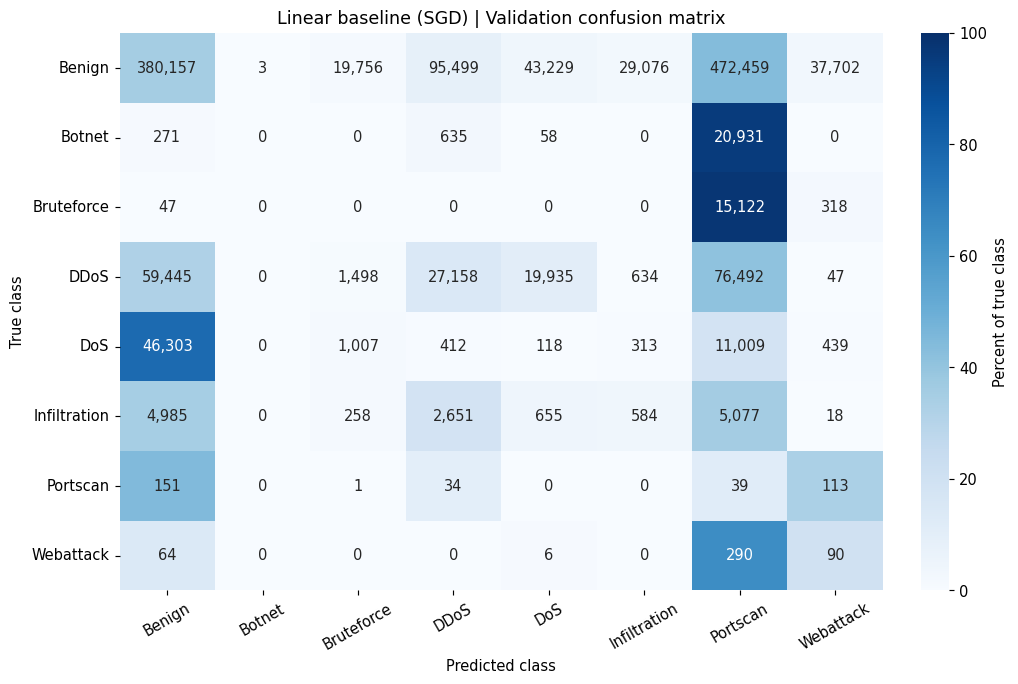

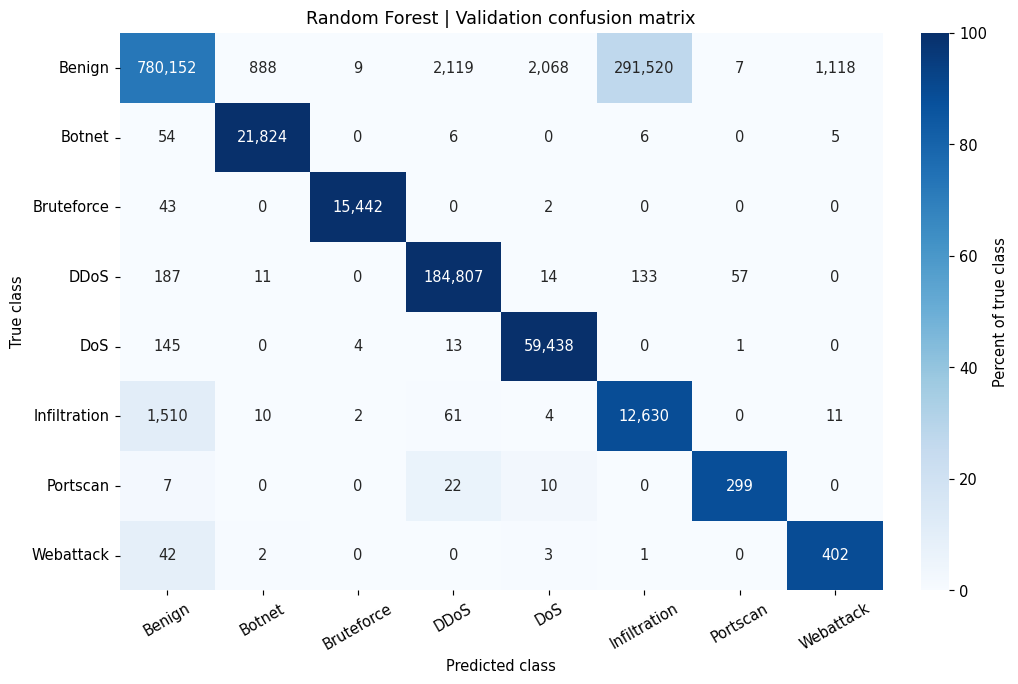

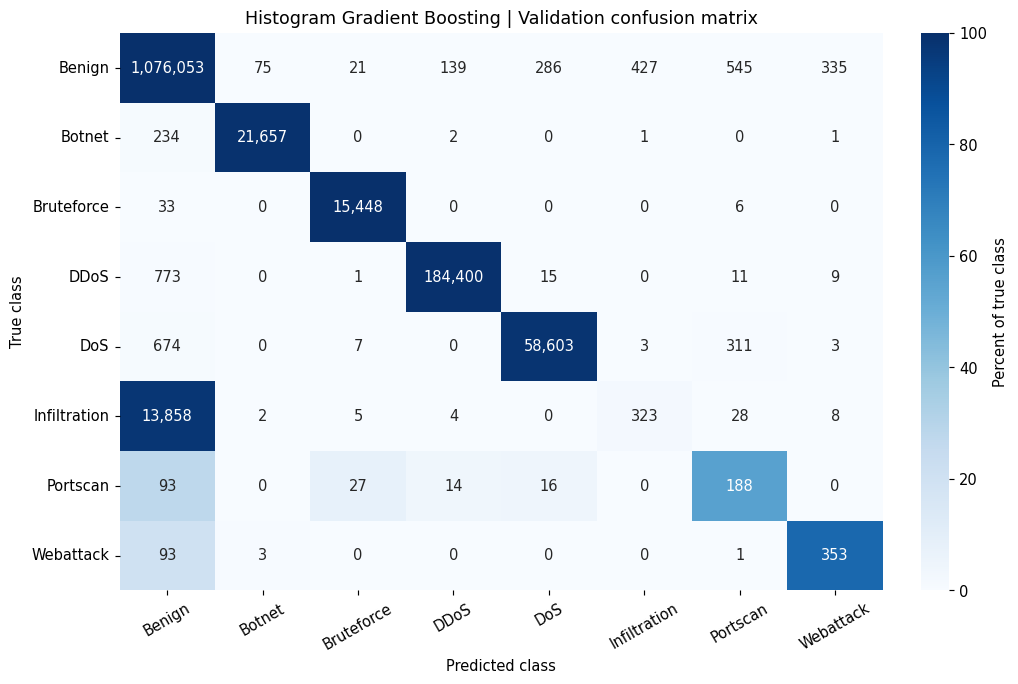

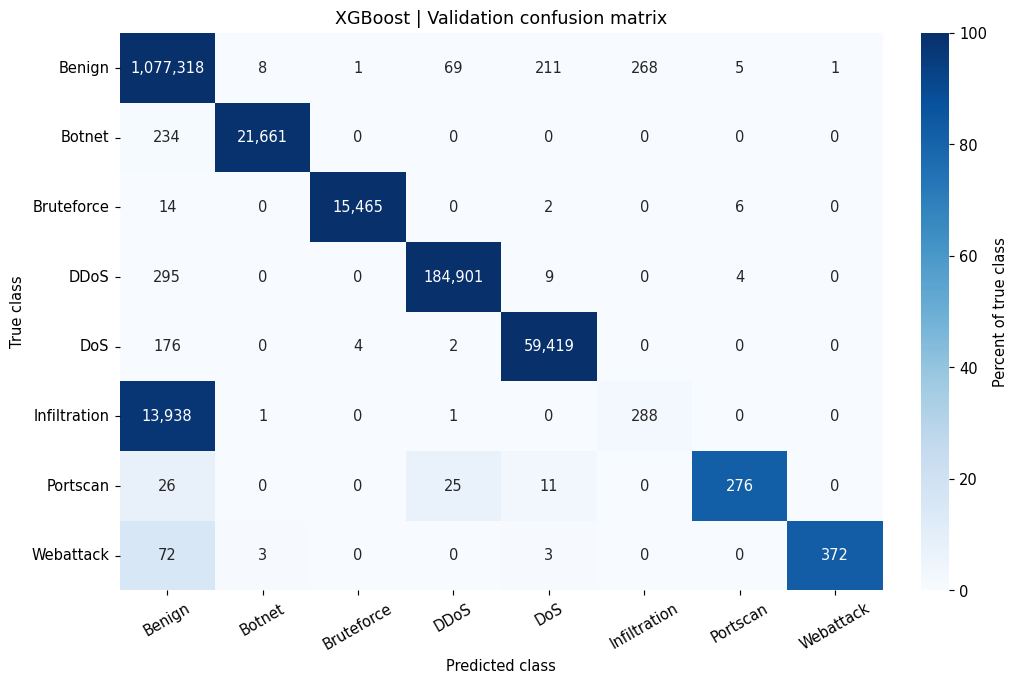

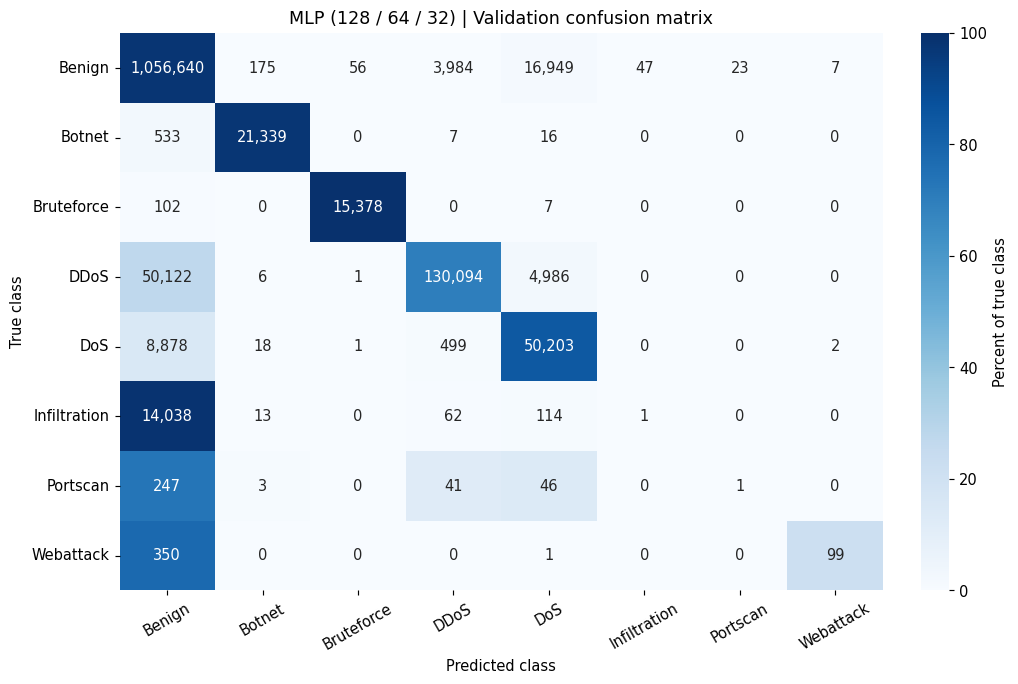

In [18]:
from sklearn.metrics import confusion_matrix

validation_predictions = {
    "majority": ("Majority baseline", np.full_like(y_val, np.argmax(np.bincount(y_train)))),
    "sgd": ("Linear baseline (SGD)", y_val_pred),
    "rf": ("Random Forest", y_pred_rf),
    "hgb": ("Histogram Gradient Boosting", y_pred_gb),
    "xgb": ("XGBoost", y_pred_xgb),
    "mlp": ("MLP (128 / 64 / 32)", y_val_pred_mlp),
}
validation_results = {
    "split": "validation",
    "classes": target_names,
    "support": np.bincount(y_val).tolist(),
    "counts": [duplicate_audit["retainedCounts"][name] for name in target_names],
    "audit": duplicate_audit,
    "models": [],
}
class_names = validation_results["classes"]
class_ids = range(len(class_names))
for model_id, (name, prediction) in validation_predictions.items():
    matrix = confusion_matrix(y_val, prediction, labels=class_ids)
    assert matrix.sum(axis=1).tolist() == validation_results["support"]
    report = classification_report(
        y_val, prediction, labels=class_ids, target_names=class_names,
        output_dict=True, zero_division=0,
    )
    validation_results["models"].append({
        "id": model_id,
        "name": name,
        "accuracy": report["accuracy"],
        "macroF1": report["macro avg"]["f1-score"],
        "perClass": [
            [report[label][metric] for metric in ("precision", "recall", "f1-score")]
            for label in class_names
        ],
        "matrix": matrix.tolist(),
        "matrixSource": "Computed on the deduplicated validation split.",
    })

(run_dir / "validation-results.json").write_text(
    json.dumps(validation_results, indent=2) + "\n", encoding="utf-8",
)

with plt.style.context("default"):
    for result in validation_results["models"]:
        counts = np.array(result["matrix"], dtype=int)
        row_percent = 100 * counts / counts.sum(axis=1, keepdims=True)

        fig, ax = plt.subplots(figsize=(9.6, 6.4), layout="constrained")
        sns.heatmap(
            row_percent, annot=counts, fmt=",d", cmap="Blues", vmin=0, vmax=100,
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={"label": "Percent of true class"}, ax=ax,
        )
        ax.set(
            title=f"{result['name']} | Validation confusion matrix",
            xlabel="Predicted class", ylabel="True class",
        )
        ax.tick_params(axis="x", labelrotation=30)
        ax.tick_params(axis="y", labelrotation=0)
        display(fig)
        plt.close(fig)

## Held-out test evaluation for the remaining models

Evaluate Linear SGD, Random Forest, Histogram Gradient Boosting and the MLP on the same 1,375,089 audited test flows used for the existing XGBoost curves. The majority baseline provides a reference. Each report shows per-class precision, recall, F1 and support, with one-vs-rest ROC-AUC and average precision. SGD probability normalization underflows on some test inputs, so its curves use the finite class decision scores. The other models use class probabilities.


Majority baseline | Test accuracy 78.39% | Macro-F1 0.1099


,precision,recall,f1-score,support,ROC-AUC,Average precision
Benign,0.7839,1.0000,0.8788,1077882,0.5,0.7839
Botnet,0.0000,0.0000,0.0000,21895,0.5,0.0159
Bruteforce,0.0000,0.0000,0.0000,15486,0.5,0.0113
DDoS,0.0000,0.0000,0.0000,185208,0.5,0.1347
DoS,0.0000,0.0000,0.0000,59602,0.5,0.0433
Infiltration,0.0000,0.0000,0.0000,14228,0.5,0.0103
Portscan,0.0000,0.0000,0.0000,339,0.5,0.0002
Webattack,0.0000,0.0000,0.0000,449,0.5,0.0003
macro avg,0.0980,0.1250,0.1099,1375089,—,—
weighted avg,0.6144,0.7839,0.6889,1375089,—,—


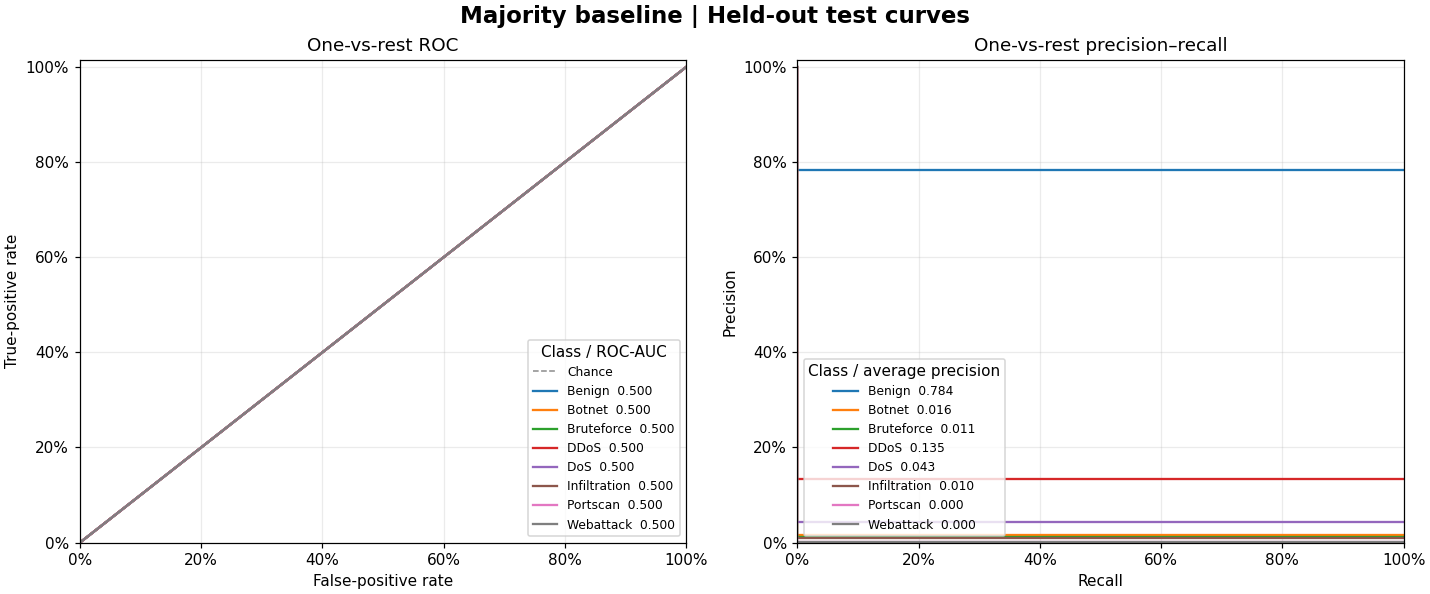

Linear baseline (SGD) | Test accuracy 29.66% | Macro-F1 0.0863


,precision,recall,f1-score,support,ROC-AUC,Average precision
Benign,0.7729,0.3524,0.4841,1077882,0.5682,0.7980
Botnet,0.0000,0.0000,0.0000,21895,0.8214,0.0422
Bruteforce,0.0000,0.0000,0.0000,15486,0.9958,0.5756
DDoS,0.2150,0.1469,0.1745,185208,0.6199,0.2144
DoS,0.0019,0.0021,0.0020,59602,0.2801,0.0293
Infiltration,0.0186,0.0402,0.0255,14228,0.4609,0.0106
Portscan,0.0001,0.1032,0.0001,339,0.4287,0.0002
Webattack,0.0023,0.1960,0.0045,449,0.8103,0.0011
macro avg,0.1264,0.1051,0.0863,1375089,—,—
weighted avg,0.6351,0.2966,0.4033,1375089,—,—


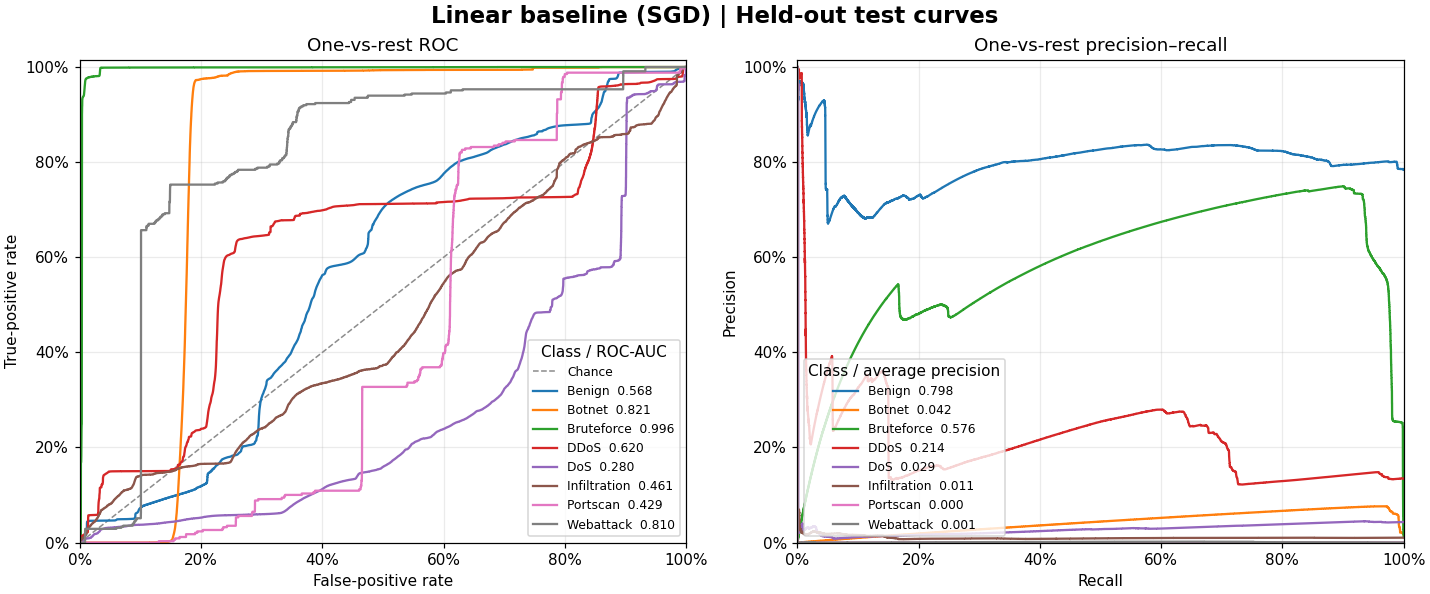

Random Forest | Test accuracy 78.20% | Macro-F1 0.7650


,precision,recall,f1-score,support,ROC-AUC,Average precision
Benign,0.9974,0.7241,0.8391,1077882,0.9935,0.9979
Botnet,0.9644,0.9973,0.9806,21895,1.0000,0.9996
Bruteforce,0.9991,0.9962,0.9976,15486,1.0000,0.9997
DDoS,0.9883,0.9980,0.9931,185208,1.0000,0.9998
DoS,0.9649,0.9974,0.9809,59602,0.9999,0.9994
Infiltration,0.0413,0.8822,0.0789,14228,0.9057,0.1286
Portscan,0.8287,0.8702,0.8489,339,0.9924,0.9097
Webattack,0.2601,0.8731,0.4008,449,0.9976,0.8453
macro avg,0.7555,0.9173,0.7650,1375089,—,—
weighted avg,0.9841,0.7820,0.8620,1375089,—,—


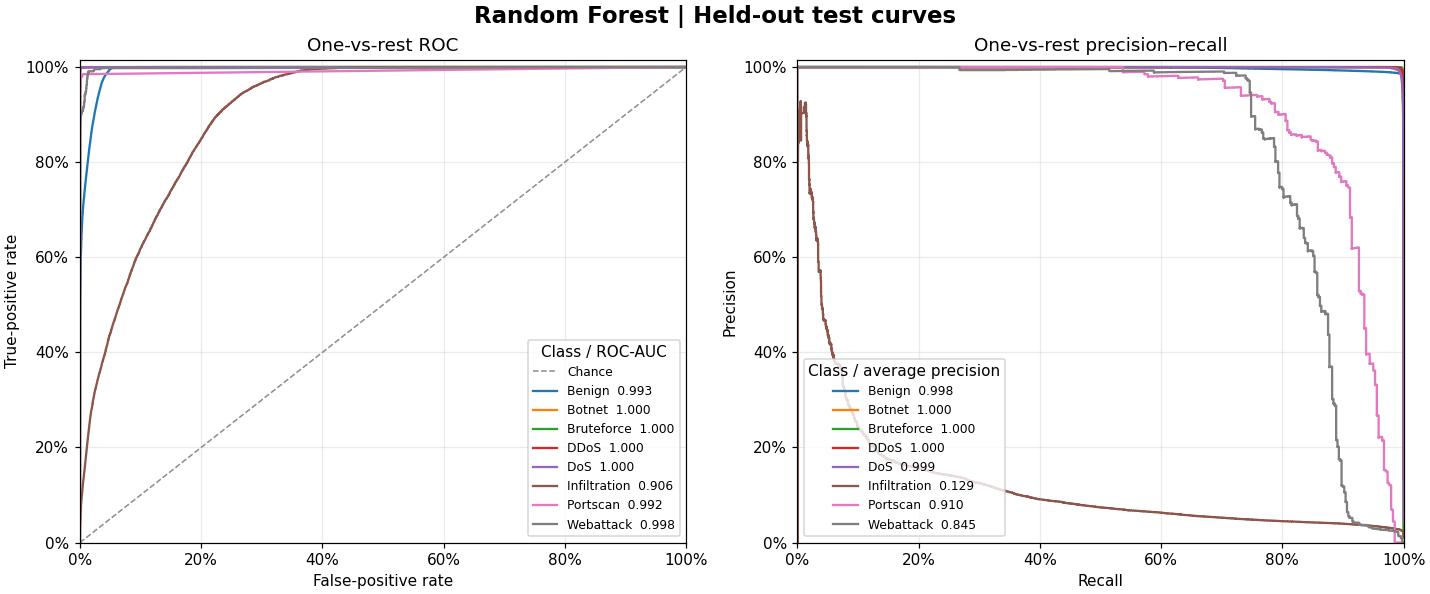

Histogram Gradient Boosting | Test accuracy 98.68% | Macro-F1 0.7317


,precision,recall,f1-score,support,ROC-AUC,Average precision
Benign,0.9855,0.9983,0.9919,1077882,0.9921,0.9975
Botnet,0.9971,0.9892,0.9931,21895,0.9994,0.9968
Bruteforce,0.9969,0.9974,0.9972,15486,0.9994,0.9946
DDoS,0.9992,0.9956,0.9974,185208,0.9997,0.9994
DoS,0.9945,0.9828,0.9886,59602,0.9949,0.9941
Infiltration,0.4378,0.0233,0.0442,14228,0.9025,0.1247
Portscan,0.1677,0.5516,0.2572,339,0.6411,0.0958
Webattack,0.4793,0.7483,0.5843,449,0.9262,0.4200
macro avg,0.7573,0.7858,0.7317,1375089,—,—
weighted avg,0.9820,0.9868,0.9824,1375089,—,—


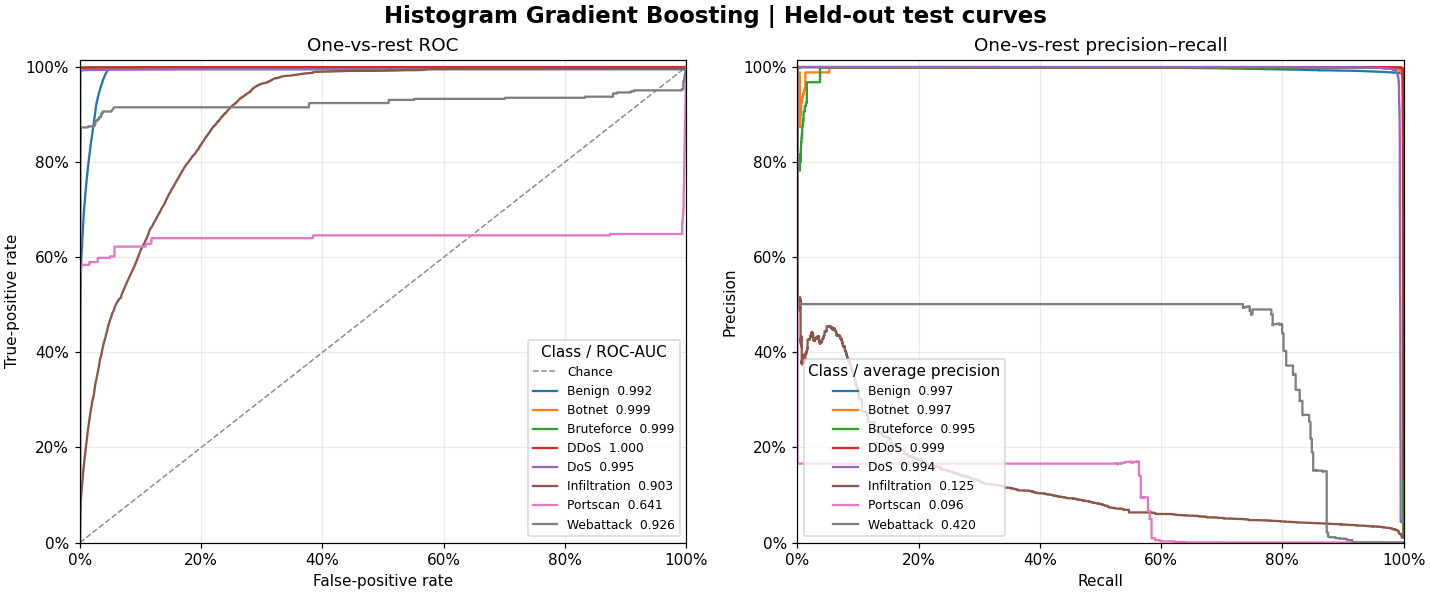

MLP (128 / 64 / 32) | Test accuracy 92.64% | Macro-F1 0.6075


,precision,recall,f1-score,support,ROC-AUC,Average precision
Benign,0.9344,0.9804,0.9569,1077882,0.8066,0.8790
Botnet,0.9894,0.9746,0.9819,21895,0.9951,0.9884
Bruteforce,0.9960,0.9910,0.9935,15486,0.9991,0.9951
DDoS,0.9655,0.7016,0.8127,185208,0.7509,0.7062
DoS,0.6947,0.8444,0.7623,59602,0.9002,0.5483
Infiltration,0.0000,0.0000,0.0000,14228,0.6028,0.0181
Portscan,0.0000,0.0000,0.0000,339,0.8074,0.1443
Webattack,0.9159,0.2183,0.3525,449,0.9004,0.6529
macro avg,0.6870,0.5888,0.6075,1375089,—,—
weighted avg,0.9199,0.9264,0.9195,1375089,—,—


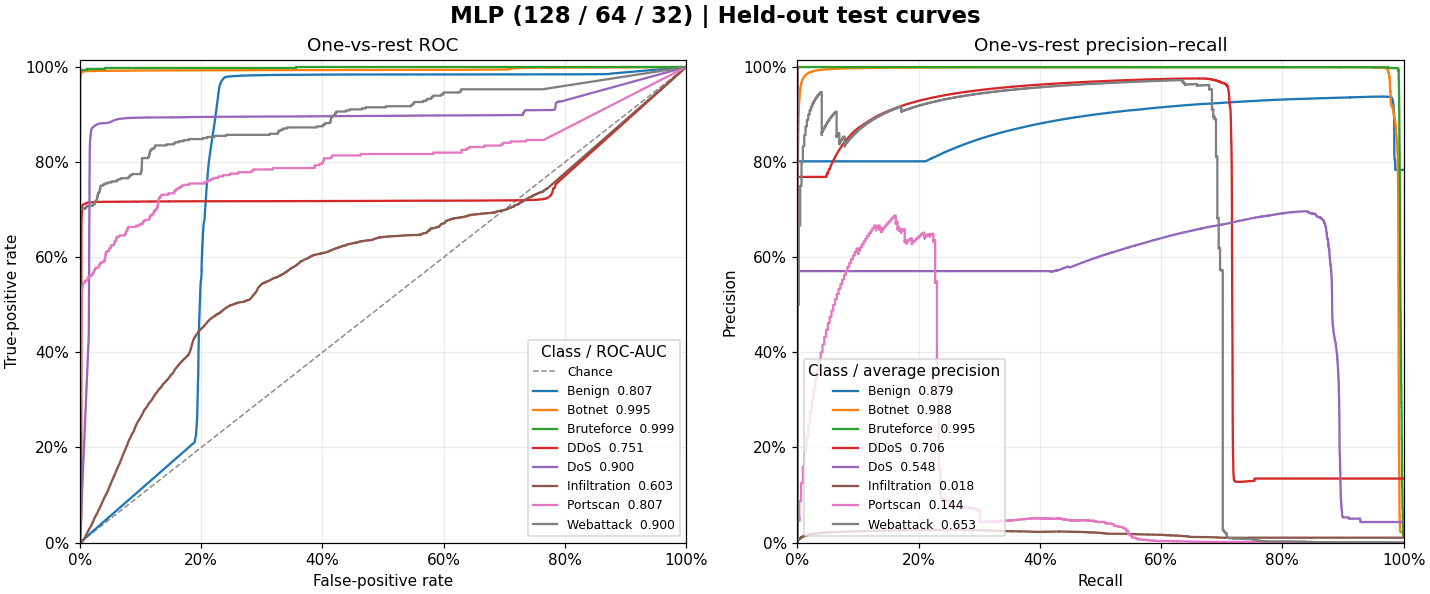

In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, classification_report, roc_auc_score
from sklearn.metrics import precision_recall_curve, roc_curve
from matplotlib.ticker import PercentFormatter


def held_out_predictions(model, features, class_ids, *, use_decision_scores=False):
    """Return hard predictions and ranking scores in the notebook's class order."""
    if not np.array_equal(model.classes_, class_ids):
        raise ValueError("Test score columns do not match the expected class order.")
    batches = [features.iloc[start:start + 65536] for start in range(0, len(features), 65536)]
    predictions = np.concatenate([model.predict(batch) for batch in batches])
    score_rows = model.decision_function if use_decision_scores else model.predict_proba
    scores = np.concatenate([score_rows(batch) for batch in batches])
    if not np.isfinite(scores).all():
        raise ValueError("Test ranking scores must be finite.")
    return predictions, scores


def report_held_out_test(name, labels, predictions, scores, class_names):
    """Summarize classification and draw per-class one-vs-rest test curves."""
    class_ids = np.arange(len(class_names))
    report = classification_report(
        labels, predictions, labels=class_ids, target_names=class_names,
        output_dict=True, zero_division=0,
    )
    class_metrics = {}
    with plt.style.context("default"):
        fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
        fig.suptitle(f"{name} | Held-out test curves", fontsize=15, fontweight="bold")
        roc_ax.plot([0, 1], [0, 1], "--", color="0.55", lw=1, label="Chance")
        colors = plt.get_cmap("tab10").colors
        for i, class_name in enumerate(class_names):
            actual = labels == i
            ranking_scores = scores[:, i]
            fpr, tpr, _ = roc_curve(actual, ranking_scores)
            precision, recall, _ = precision_recall_curve(actual, ranking_scores)
            auc = roc_auc_score(actual, ranking_scores)
            ap = average_precision_score(actual, ranking_scores)
            class_metrics[class_name] = {"rocAuc": auc, "averagePrecision": ap}
            roc_ax.plot(fpr, tpr, color=colors[i], lw=1.5, label=f"{class_name}  {auc:.3f}")
            pr_ax.step(recall, precision, where="post", color=colors[i], lw=1.5,
                       label=f"{class_name}  {ap:.3f}")

        roc_ax.set(title="One-vs-rest ROC", xlabel="False-positive rate", ylabel="True-positive rate")
        pr_ax.set(title="One-vs-rest precision–recall", xlabel="Recall", ylabel="Precision")
        for axis, legend_title, location in (
            (roc_ax, "Class / ROC-AUC", "lower right"),
            (pr_ax, "Class / average precision", "lower left"),
        ):
            axis.set(xlim=(0, 1), ylim=(0, 1.015))
            axis.xaxis.set_major_formatter(PercentFormatter(1))
            axis.yaxis.set_major_formatter(PercentFormatter(1))
            axis.grid(alpha=0.25)
            axis.legend(title=legend_title, loc=location, fontsize=8)

    table = pd.DataFrame(report).T.drop(index="accuracy")
    table["support"] = table["support"].astype(int)
    table.loc[class_names, "ROC-AUC"] = [class_metrics[label]["rocAuc"] for label in class_names]
    table.loc[class_names, "Average precision"] = [
        class_metrics[label]["averagePrecision"] for label in class_names
    ]
    print(f"{name} | Test accuracy {report['accuracy']:.2%} | Macro-F1 {report['macro avg']['f1-score']:.4f}")
    display(table.round(4))
    display(fig)
    plt.close(fig)
    return {
        "name": name,
        "report": report,
        "ranking": class_metrics,
        "macroRocAuc": float(np.mean([row["rocAuc"] for row in class_metrics.values()])),
        "macroAveragePrecision": float(np.mean([row["averagePrecision"] for row in class_metrics.values()])),
    }

held_out_models = {
    "majority": ("Majority baseline", DummyClassifier(strategy="most_frequent").fit(X_train, y_train)),
    "sgd": ("Linear baseline (SGD)", baseline_pipeline),
    "rf": ("Random Forest", rf_model),
    "hgb": ("Histogram Gradient Boosting", gb_model),
    "mlp": ("MLP (128 / 64 / 32)", mlp_pipeline),
}

test_results = {
    "split": "test",
    "classes": target_names,
    "support": np.bincount(y_test, minlength=len(target_names)).tolist(),
    "models": {},
}
for model_id, (name, model) in held_out_models.items():
    use_decision_scores = model_id == "sgd"
    prediction, scores = held_out_predictions(
        model, X_test, np.arange(len(target_names)), use_decision_scores=use_decision_scores,
    )
    test_results["models"][model_id] = report_held_out_test(
        name, np.asarray(y_test), prediction, scores, target_names,
    )
    test_results["models"][model_id]["rankingScore"] = (
        "decision_function" if use_decision_scores else "predict_proba"
    )

(run_dir / "test-results.json").write_text(
    json.dumps(test_results, indent=2) + "\n", encoding="utf-8",
)
